# 49 — Stratification Analysis: Osaka Bay vs. Hiroshima Bay

This notebook demonstrates how to load, process, and analyze water column stratification in two major coastal systems in the Seto Inland Sea: **Osaka Bay** and **Hiroshima Bay**.

We explore the five key oceanographic figures to examine the degree of stratification:
1. **Vertical Profiles** (Depth vs. Temperature/Salinity/Density) at key stations.
2. **Vertical Transect Contour Plots** (Depth vs. Station) along a line.
3. **Spatial Map of Stratification Indices** ($\Delta T$, $\Delta S$, or $\Delta \rho$).
4. **Temporal Depth-Time Heatmaps** (Month vs. Depth) showing the seasonal lifecycle.
5. **Temperature-Salinity (T-S) Diagrams** showing water mass stacking.

## 1. Imports & Setup

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import gsw
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.interpolate import griddata

# Set styling
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'figure.titlesize': 16
})

## 2. Data Loading & Coordinate Mapping

We load the raw survey datasets for both bays. For Osaka Bay, coordinates are loaded from `station_meta.csv`. For Hiroshima Bay, coordinates are extracted from the processed `merged_gdf.feather` file, which maps the station IDs to their latitude and longitude.

In [9]:
# File paths
osaka_data_path = "../data/raw/Fixed_line_survey/fixed_line_survey_long_osaka.csv"
osaka_meta_path = "../data/raw/Fixed_line_survey/station_meta.csv"

hiroshima_data_path = "../data/raw/Fixed_line_survey/fixed_line_survey_long_hiroshima.csv"

# Load Osaka Bay
df_osaka = pd.read_csv(osaka_data_path)
meta_osaka = pd.read_csv(osaka_meta_path)

# Load Hiroshima Bay
df_hiroshima = pd.read_csv(hiroshima_data_path)

# Helper function to convert "Degrees Minutes" (e.g. "34 21.13") to Decimal Degrees
def dms_to_dd(dms_str):
    parts = str(dms_str).strip().split()
    if len(parts) == 2:
        return float(parts[0]) + float(parts[1]) / 60.0
    return np.nan

meta_osaka['Latitude'] = meta_osaka['Latitude_N'].apply(dms_to_dd)
meta_osaka['Longitude'] = meta_osaka['Longitude_E'].apply(dms_to_dd)

# Merge Osaka Coordinates
df_osaka = df_osaka.merge(meta_osaka, left_on='Station', right_on='Station_ID', how='left')

# Hiroshima Station Coordinates
# Extracted directly from Row 1 of the Hiroshima survey PDF (587628.pdf).
# The PDF uses a local station numbering system (1, 2, 4, 6, ...) which is
# different from the national 'renban' IDs in merged_gdf.feather (390, 396, ...).
# Format: Station_ID -> (Latitude_N, Longitude_E) in decimal degrees.
hiroshima_station_coords = {
    1:  (34.200000, 132.600000),
    2:  (34.216667, 132.783333),
    4:  (34.366667, 133.116667),
    6:  (34.366667, 133.350000),
    7:  (34.116667, 132.783333),
    13: (34.183333, 132.350000),
    15: (34.300000, 132.366667),
    17: (34.316667, 132.383333),
    18: (34.333333, 132.383333),
    19: (34.350000, 132.466667),
    20: (34.316667, 132.483333),
    21: (34.233333, 132.516667),
    24: (34.383333, 133.383333),
    33: (34.266667, 132.266667),
    34: (34.233333, 132.450000),
    35: (34.166667, 132.550000),
    36: (34.366667, 133.383333),
    37: (34.416667, 133.416667),
    38: (34.400000, 133.233333),
}

df_hiroshima['Latitude'] = df_hiroshima['Station'].map(lambda s: hiroshima_station_coords.get(s, (np.nan, np.nan))[0])
df_hiroshima['Longitude'] = df_hiroshima['Station'].map(lambda s: hiroshima_station_coords.get(s, (np.nan, np.nan))[1])

print(f"Osaka: {len(df_osaka)} rows, {df_osaka['Latitude'].notna().sum()} with coordinates")
print(f"Hiroshima: {len(df_hiroshima)} rows, {df_hiroshima['Latitude'].notna().sum()} with coordinates")

Osaka: 1143 rows, 1143 with coordinates
Hiroshima: 1199 rows, 1199 with coordinates


## 3. Calculating Stratification Indices

We compute the potential density anomaly $\sigma_0$ using the Gibbs SeaWater (GSW) toolbox.
We then calculate three stratification indicators:
1. **Density Difference ($\Delta\rho$):** $\sigma_{0,\text{bottom}} - \sigma_{0,\text{surface}}$
2. **Temperature Difference ($\Delta T$):** $T_{\text{surface}} - T_{\text{bottom}}$
3. **Salinity Difference ($\Delta S$):** $S_{\text{bottom}} - S_{\text{surface}}$

In [10]:
def compute_density_and_stratification(df):
    # Map Depth to numeric values
    def get_numeric_depth(row):
        depth_str = str(row['Depth']).strip()
        if depth_str == 'Bottom':
            return float(row.get('Nominal_Depth_m', 20.0))
        elif depth_str.endswith('m'):
            return float(depth_str[:-1])
        return np.nan

    df['Numeric_Depth'] = df.apply(get_numeric_depth, axis=1)
    
    # Calculate density (sigma0)
    SP = df['Salinity'].values
    t = df['Temperature'].values
    lon = df['Longitude'].values
    lat = df['Latitude'].values
    
    # Drop rows without S and T for density calculation
    valid = ~np.isnan(SP) & ~np.isnan(t)
    df['Density'] = np.nan
    if valid.any():
        SA = gsw.SA_from_SP(SP[valid], 0, lon[valid], lat[valid])
        # Conservative Temperature
        CT = gsw.CT_from_t(SA, t[valid], 0)
        df.loc[valid, 'Density'] = gsw.sigma0(SA, CT)

    # Pivot to separate surface and bottom rows
    surf = df[df['Depth'] == '0m'][['Month', 'Station', 'Density', 'Numeric_Depth', 'Salinity', 'Temperature', 'Latitude', 'Longitude']].copy()
    bot = df[df['Depth'] == 'Bottom'][['Month', 'Station', 'Density', 'Numeric_Depth', 'Salinity', 'Temperature']].copy()
    
    surf = surf.rename(columns={'Density': 'density_surf', 'Numeric_Depth': 'depth_surf', 'Salinity': 'sal_surf', 'Temperature': 'temp_surf'})
    bot = bot.rename(columns={'Density': 'density_bot', 'Numeric_Depth': 'depth_bot', 'Salinity': 'sal_bot', 'Temperature': 'temp_bot'})
    
    paired = pd.merge(surf, bot, on=['Month', 'Station'], how='inner')
    
    paired['Delta_Rho'] = paired['density_bot'] - paired['density_surf']
    paired['Delta_T'] = paired['temp_surf'] - paired['temp_bot']
    paired['Delta_S'] = paired['sal_bot'] - paired['sal_surf']
    
    # Normalize by depth interval for the gradient
    depth_diff = paired['depth_bot'] - paired['depth_surf']
    depth_diff = depth_diff.replace(0, np.nan)
    paired['Delta_Rho_dz'] = paired['Delta_Rho'] / depth_diff
    
    return df, paired

# Run calculation for both bays
df_osaka, paired_osaka = compute_density_and_stratification(df_osaka)
df_hiroshima, paired_hiroshima = compute_density_and_stratification(df_hiroshima)

print("Osaka paired records:", len(paired_osaka))
print("Hiroshima paired records:", len(paired_hiroshima))

Osaka paired records: 240
Hiroshima paired records: 228


## 4. Figure 1: Vertical Profiles

Vertical profiles show how temperature and salinity vary from the surface to the bottom. Let's compare a strongly stratified summer month (July) with a well-mixed winter month (January) at a selected station.

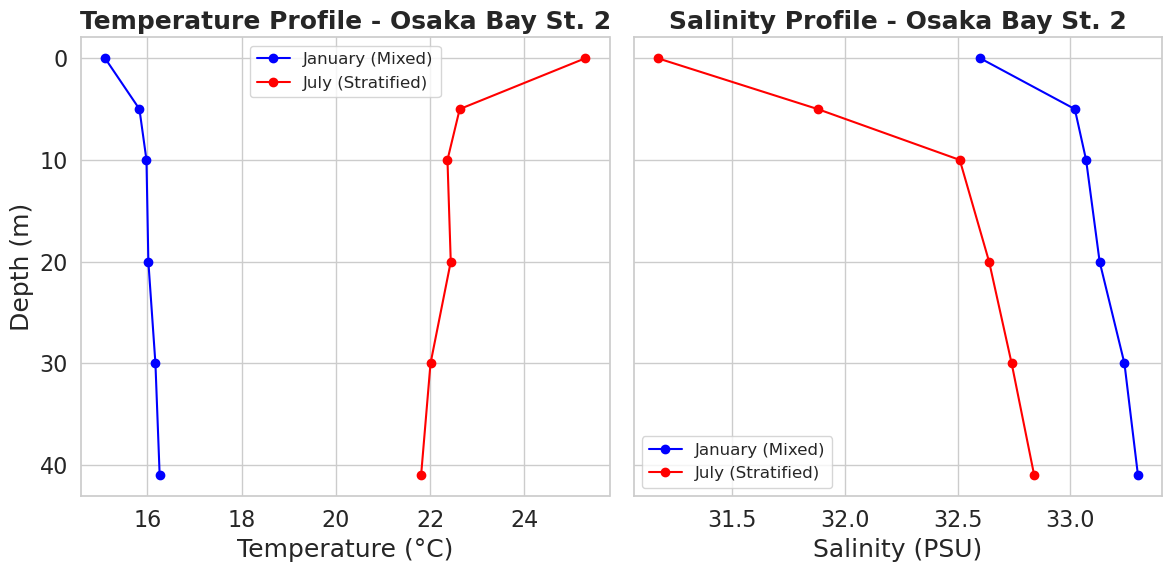

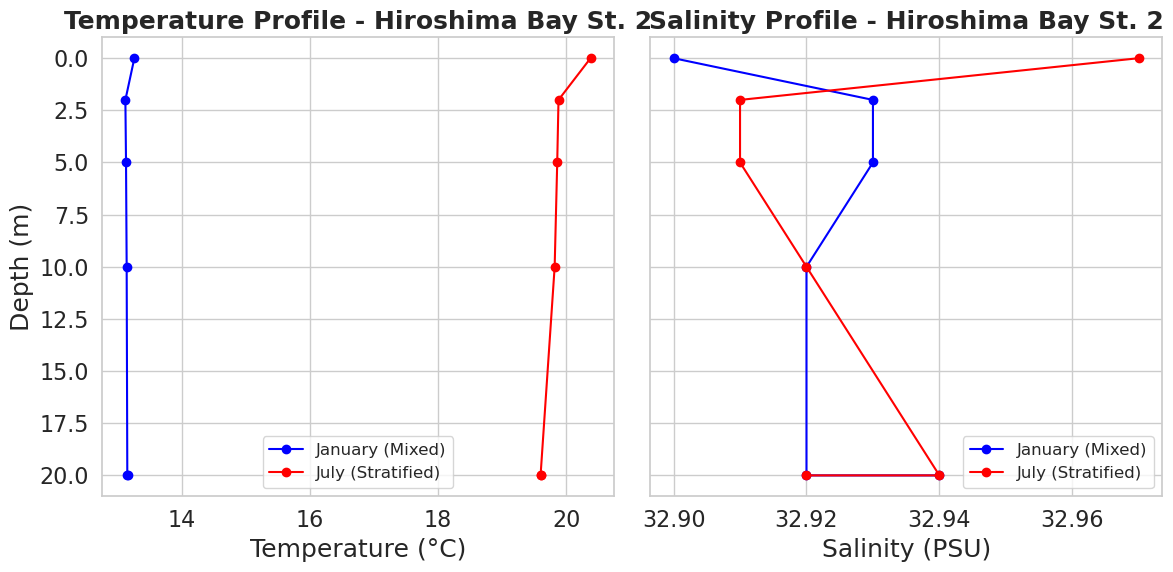

In [11]:
def plot_vertical_profiles(df, station_id, bay_name):
    # Filter for January (Month 1) and July (Month 7)
    jan_data = df[(df['Station'] == station_id) & (df['Month'] == 1)].sort_values('Numeric_Depth')
    july_data = df[(df['Station'] == station_id) & (df['Month'] == 7)].sort_values('Numeric_Depth')
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
    
    # Temperature Profile
    axes[0].plot(jan_data['Temperature'], jan_data['Numeric_Depth'], 'o-', label='January (Mixed)', color='blue')
    axes[0].plot(july_data['Temperature'], july_data['Numeric_Depth'], 'o-', label='July (Stratified)', color='red')
    axes[0].set_xlabel('Temperature (°C)')
    axes[0].set_ylabel('Depth (m)')
    axes[0].invert_yaxis()
    axes[0].set_title(f'Temperature Profile - {bay_name} St. {station_id}')
    axes[0].legend()
    axes[0].grid(True)
    
    # Salinity Profile
    axes[1].plot(jan_data['Salinity'], jan_data['Numeric_Depth'], 'o-', label='January (Mixed)', color='blue')
    axes[1].plot(july_data['Salinity'], july_data['Numeric_Depth'], 'o-', label='July (Stratified)', color='red')
    axes[1].set_xlabel('Salinity (PSU)')
    axes[1].set_title(f'Salinity Profile - {bay_name} St. {station_id}')
    axes[1].legend()
    axes[1].grid(True)
    
    plt.tight_layout()
    plt.show()

# Plot for Osaka Station 2 (deep water) and Hiroshima Station 2
plot_vertical_profiles(df_osaka, station_id=2, bay_name='Osaka Bay')
plot_vertical_profiles(df_hiroshima, station_id=2, bay_name='Hiroshima Bay')

## 5. Figure 2: Vertical Transect Contour Plots

A vertical transect represents a cross-section of the water column along a line of stations. We interpolate the discrete depth points across all stations to plot continuous contours of temperature and salinity in July.

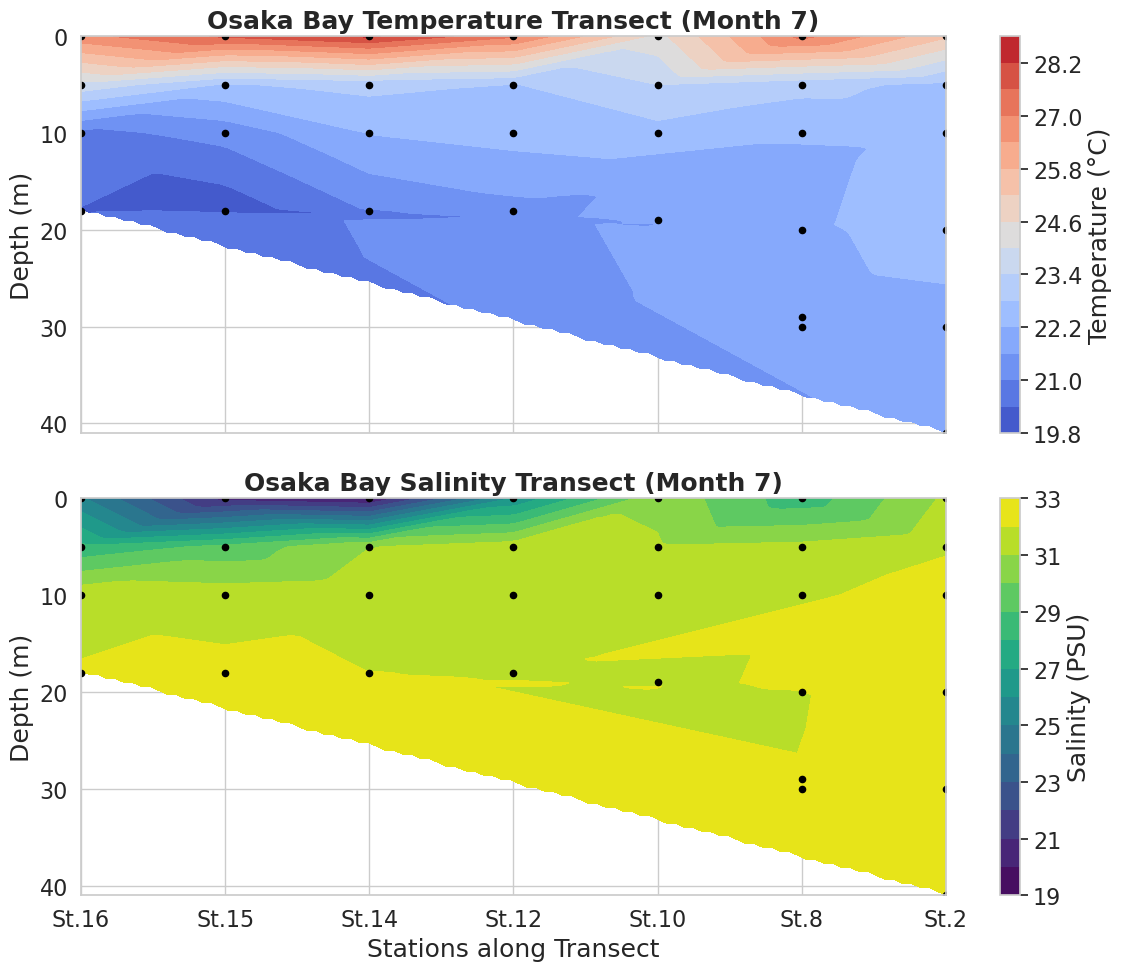

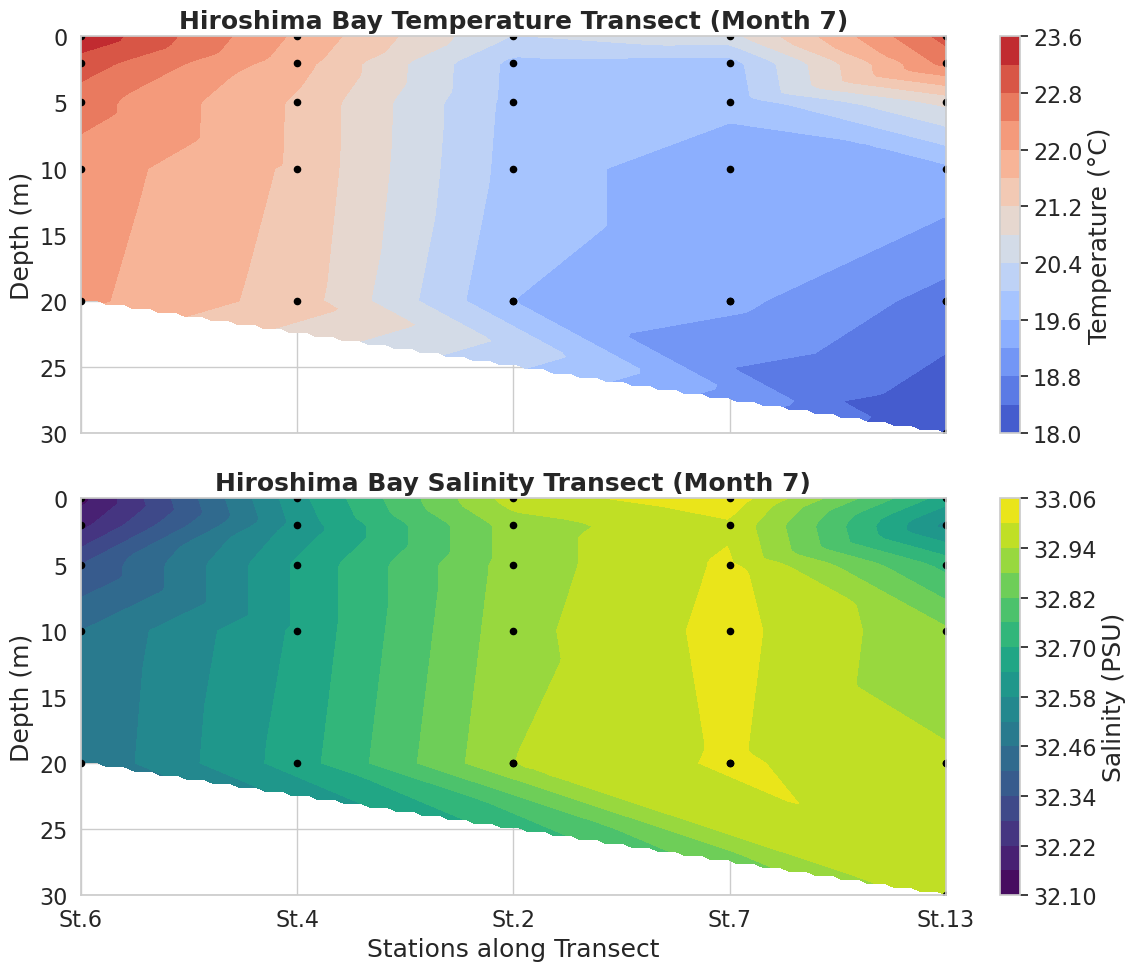

In [12]:
def plot_vertical_transect(df, month, bay_name, stations_line):
    # Filter data for the specified line of stations in the chosen month
    line_data = df[(df['Month'] == month) & (df['Station'].isin(stations_line))].copy()
    line_data = line_data.dropna(subset=['Temperature', 'Salinity', 'Numeric_Depth'])
    
    if line_data.empty:
        print(f"No data available for {bay_name} transect.")
        return
        
    # Extract coordinates
    st_idx = {st: i for i, st in enumerate(stations_line)}
    line_data['Station_Dist'] = line_data['Station'].map(st_idx)
    
    x = line_data['Station_Dist'].values
    y = line_data['Numeric_Depth'].values
    z_temp = line_data['Temperature'].values
    z_sal = line_data['Salinity'].values
    
    # Create regular grid for interpolation
    grid_x, grid_y = np.mgrid[0:len(stations_line)-1:100j, y.min():y.max():100j]
    
    # Interpolate
    grid_temp = griddata((x, y), z_temp, (grid_x, grid_y), method='linear')
    grid_sal = griddata((x, y), z_sal, (grid_x, grid_y), method='linear')
    
    fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True, sharey=True)
    
    # Temperature Transect
    t_contour = axes[0].contourf(grid_x, grid_y, grid_temp, levels=15, cmap='coolwarm')
    fig.colorbar(t_contour, ax=axes[0], label='Temperature (°C)')
    axes[0].scatter(x, y, color='black', s=20)
    axes[0].set_ylabel('Depth (m)')
    axes[0].set_title(f'{bay_name} Temperature Transect (Month {month})')
    axes[0].invert_yaxis()
    
    # Salinity Transect
    s_contour = axes[1].contourf(grid_x, grid_y, grid_sal, levels=15, cmap='viridis')
    fig.colorbar(s_contour, ax=axes[1], label='Salinity (PSU)')
    axes[1].scatter(x, y, color='black', s=20)
    axes[1].set_ylabel('Depth (m)')
    axes[1].set_xlabel('Stations along Transect')
    axes[1].set_xticks(range(len(stations_line)))
    axes[1].set_xticklabels([f"St.{st}" for st in stations_line])
    axes[1].set_title(f'{bay_name} Salinity Transect (Month {month})')
    
    plt.tight_layout()
    plt.show()

# Define transect lines (stations sorted from inner bay to outer channel)
osaka_line = [16, 15, 14, 12, 10, 8, 2]
hiroshima_line = [6, 4, 2, 7, 13]

plot_vertical_transect(df_osaka, month=7, bay_name='Osaka Bay', stations_line=osaka_line)
plot_vertical_transect(df_hiroshima, month=7, bay_name='Hiroshima Bay', stations_line=hiroshima_line)

## 6. Figure 3: Spatial Maps of Stratification Indices

We visualize the geographic distribution of stratification intensity using the density difference index ($\Delta\rho$). Areas with high $\Delta\rho$ are highly stratified (stable), while areas near zero are well-mixed.

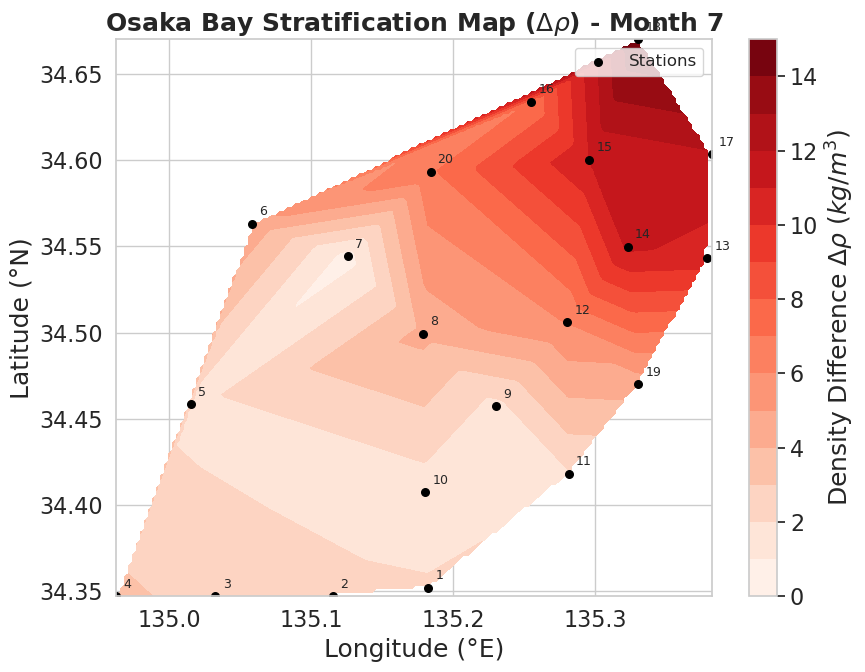

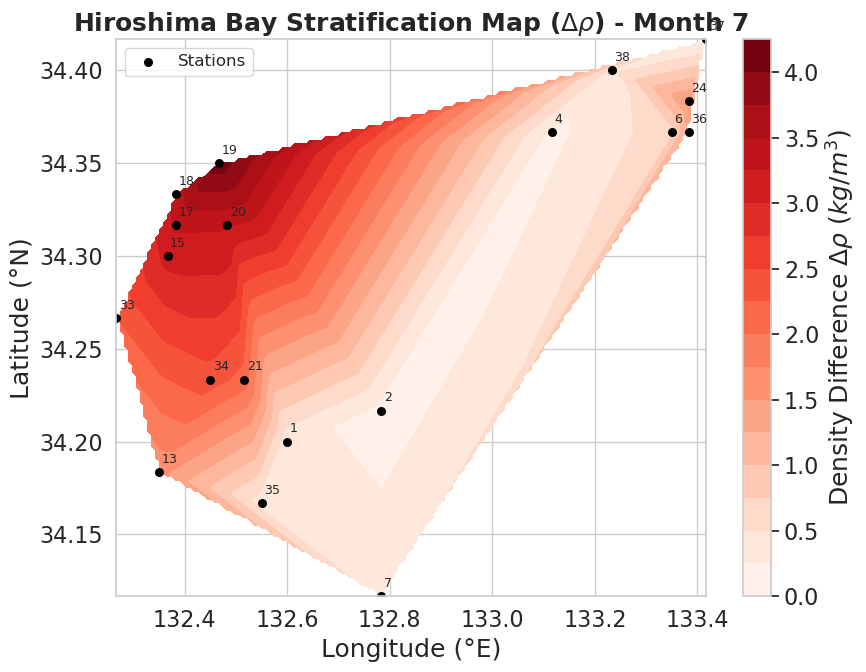

In [13]:
def plot_spatial_stratification(paired_df, month, bay_name):
    # Filter for selected month
    month_data = paired_df[paired_df['Month'] == month].dropna(subset=['Latitude', 'Longitude', 'Delta_Rho'])
    
    if month_data.empty:
        print(f"No spatial data available for {bay_name} in Month {month}.")
        return
        
    x = month_data['Longitude'].values
    y = month_data['Latitude'].values
    z = month_data['Delta_Rho'].values
    
    # Create regular grid
    grid_x, grid_y = np.mgrid[x.min():x.max():150j, y.min():y.max():150j]
    
    # Interpolate
    grid_z = griddata((x, y), z, (grid_x, grid_y), method='linear')
    
    plt.figure(figsize=(9, 7))
    contour = plt.contourf(grid_x, grid_y, grid_z, levels=15, cmap='Reds')
    plt.colorbar(contour, label='Density Difference $\Delta\\rho$ ($kg/m^3$)')
    plt.scatter(x, y, color='black', marker='o', s=30, label='Stations')
    
    # Annotate station numbers
    for _, row in month_data.iterrows():
        plt.text(row['Longitude']+0.005, row['Latitude']+0.005, f"{int(row['Station'])}", fontsize=9)
        
    plt.xlabel('Longitude (°E)')
    plt.ylabel('Latitude (°N)')
    plt.title(f'{bay_name} Stratification Map ($\Delta\\rho$) - Month {month}')
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_spatial_stratification(paired_osaka, month=7, bay_name='Osaka Bay')
plot_spatial_stratification(paired_hiroshima, month=7, bay_name='Hiroshima Bay')

### Monthly Climatological Stratification (All Months)

To visualize the seasonal evolution of stratification across the entire bay, we plot the climatological mean of density difference ($\Delta\rho$) for all 12 months in a 4x3 subplot format, overlaying coastlines and land boundaries using Cartopy.

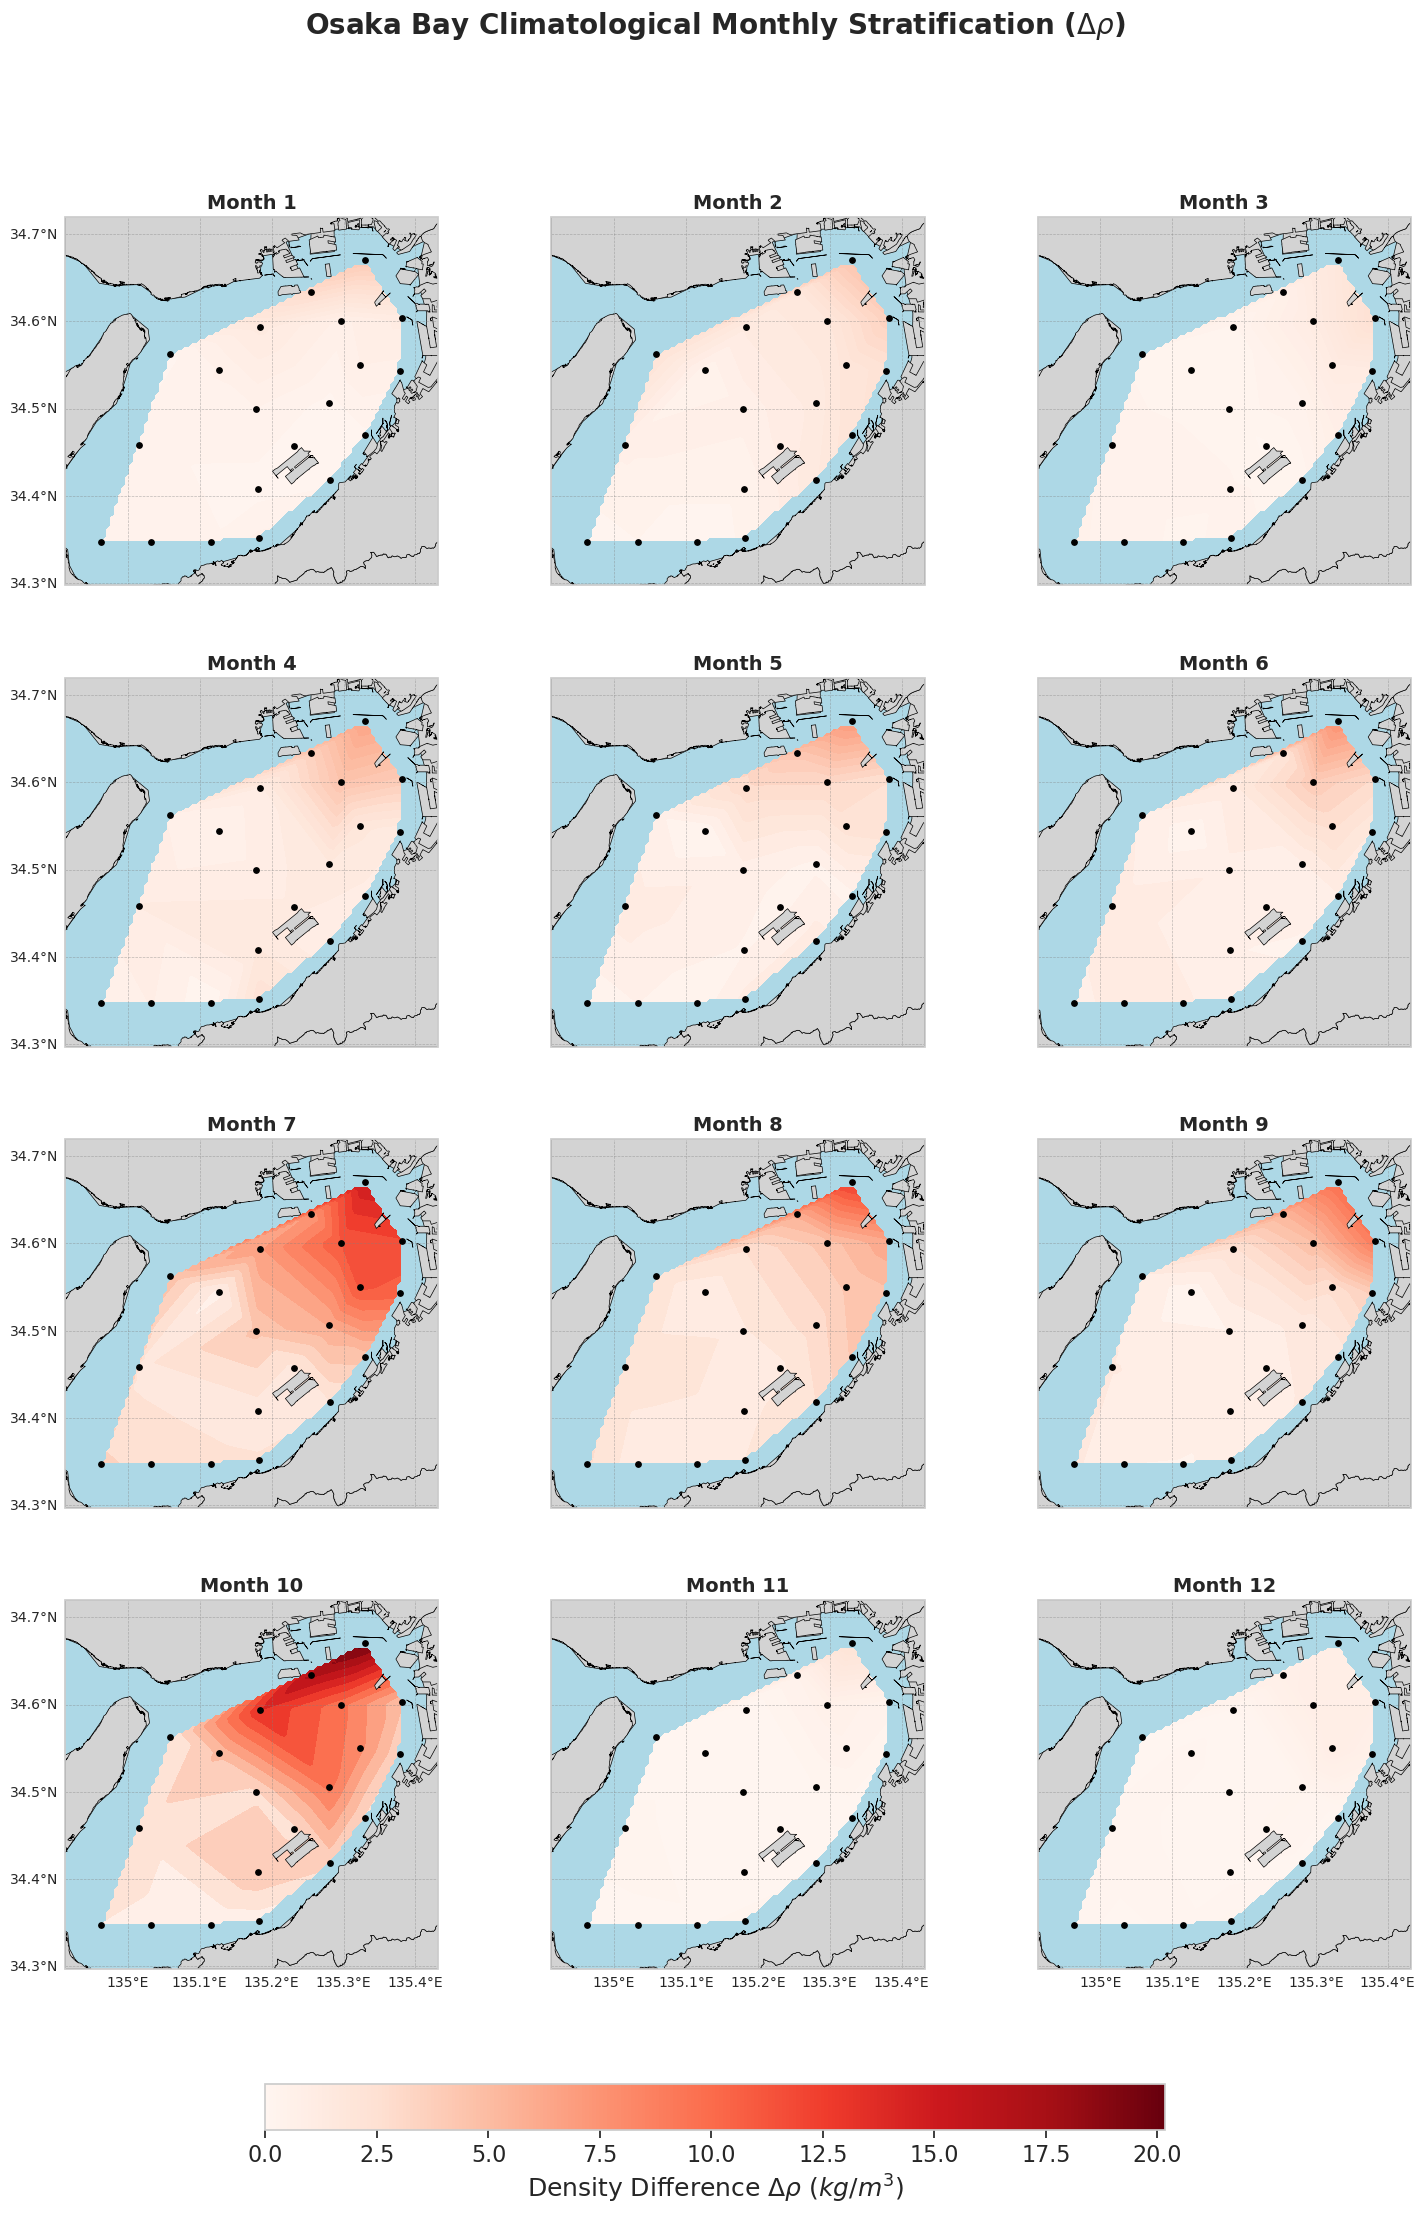

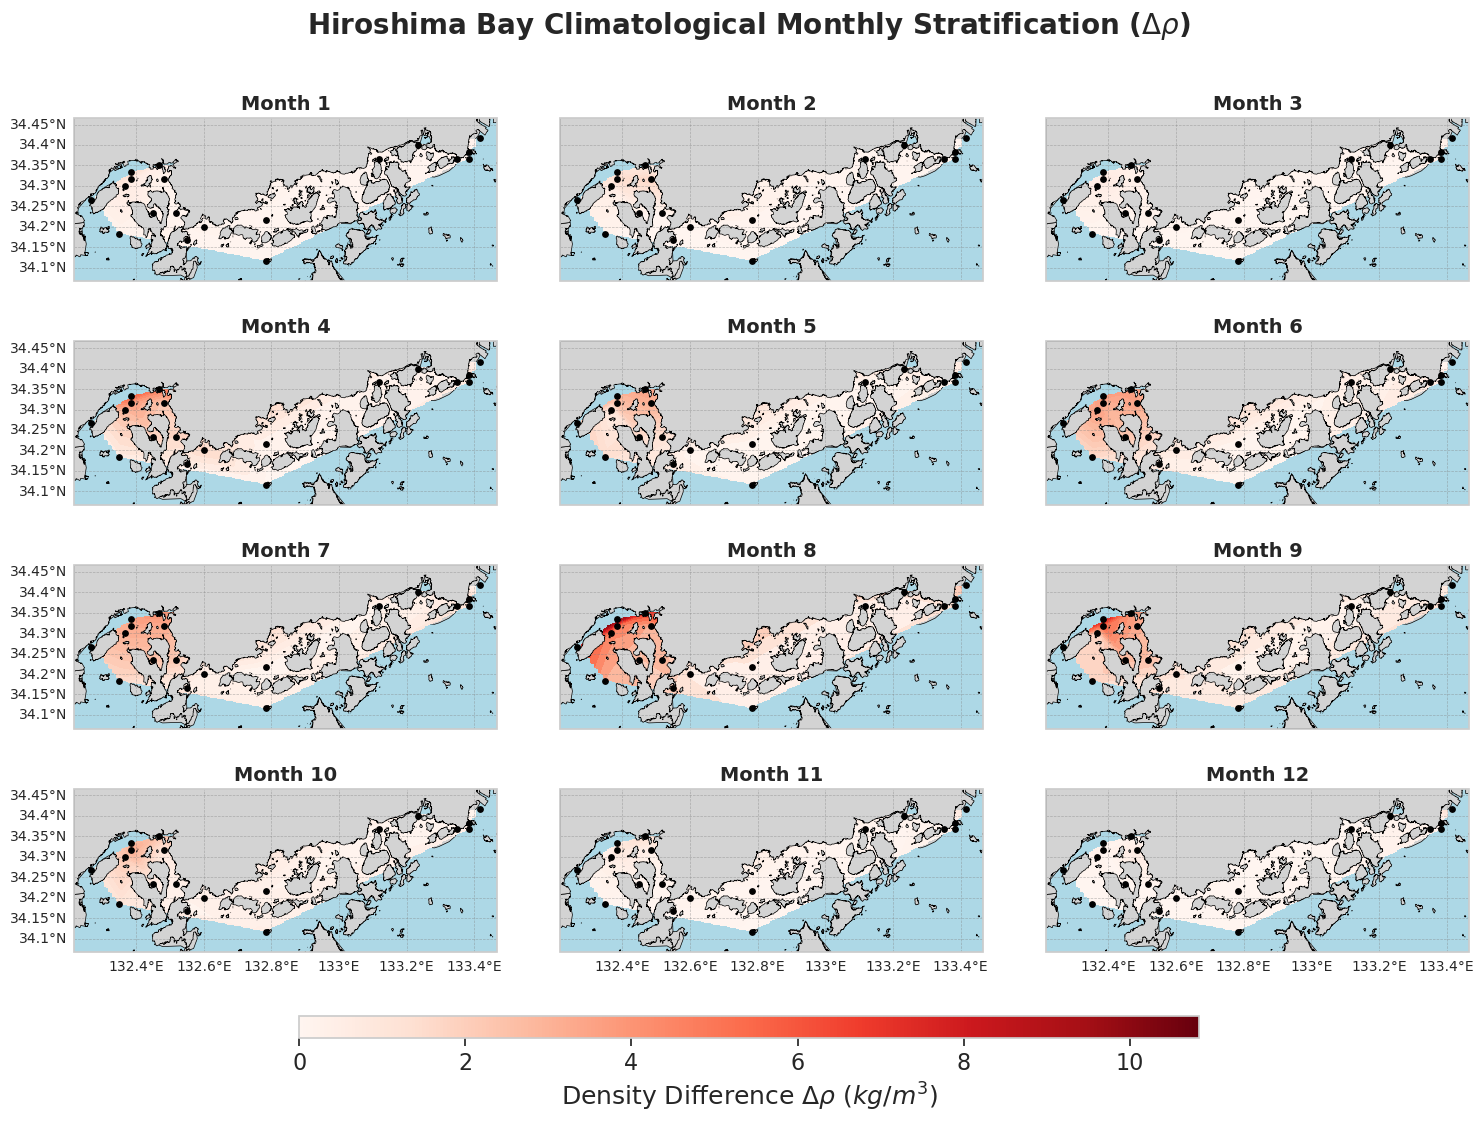

In [18]:
from shapely.geometry import box

# Load the land boundary once globally/outside the function to avoid redundant disk reads/reprojection
land_boundary_file = MappingConfig.get_boundary_file("Seto Inland Sea")
land_boundary_path = ProjectPaths.BOUNDARIES_DIR / "SIS_prefecture_boundaries" / land_boundary_file
global_sis_land_boundary = gpd.read_file(land_boundary_path)
if global_sis_land_boundary.crs != "EPSG:4326":
    global_sis_land_boundary = global_sis_land_boundary.to_crs("EPSG:4326")

def plot_monthly_climatology_stratification(paired_df, bay_name, land_boundary):
    # Group by Month and Station to get the climatological mean
    monthly_means = paired_df.groupby(['Month', 'Station'])[['Longitude', 'Latitude', 'Delta_Rho']].mean().reset_index()
    
    # Define extent based on station coordinates
    x_coords = monthly_means['Longitude'].dropna().values
    y_coords = monthly_means['Latitude'].dropna().values
    extent = [x_coords.min() - 0.05, x_coords.max() + 0.05, y_coords.min() - 0.05, y_coords.max() + 0.05]
    
    # --- OPTIMIZATION 1: Clip shapefile to extent once before plotting loop ---
    bbox = box(extent[0], extent[2], extent[1], extent[3])
    # Clip land boundaries to mapping extent to dramatically speed up rendering
    local_land_boundary = gpd.clip(land_boundary, bbox)
    
    # --- OPTIMIZATION 2: Pre-compute interpolation grid mesh once ---
    grid_x, grid_y = np.mgrid[extent[0]:extent[1]:100j, extent[2]:extent[3]:100j]
    
    aspect_ratio = (extent[3] - extent[2]) / (extent[1] - extent[0])
    fig_width = 18
    width_per_subplot = fig_width / 3
    height_per_subplot = (width_per_subplot * aspect_ratio) + 0.5  # Buffer for titles
    fig_height = (height_per_subplot * 4) + 1.5                   # Buffer for colorbar at bottom
    
    # Base Figure Setup
    fig, axes = plt.subplots(4, 3, figsize=(fig_width, fig_height), subplot_kw={'projection': ccrs.PlateCarree()})
    axes = axes.flatten()
    
    # Set global ocean background
    for ax in axes:
        ax.set_facecolor(MappingConfig.COLOR_OCEAN)
        
    # Consistent color limits for direct comparison across months
    vmin = max(0.0, monthly_means['Delta_Rho'].min())
    vmax = monthly_means['Delta_Rho'].max()
    if np.isnan(vmin) or np.isnan(vmax):
        vmin, vmax = 0.0, 5.0
        
    for month in range(1, 13):
        ax = axes[month - 1]
        month_data = monthly_means[monthly_means['Month'] == month].dropna(subset=['Latitude', 'Longitude', 'Delta_Rho'])
        
        # Set spatial extent
        ax.set_extent(extent, crs=ccrs.PlateCarree())
        
        # Add Cartopy background features
        ax.add_feature(cfeature.LAND, facecolor=MappingConfig.COLOR_LAND, zorder=MappingConfig.ZORDER_CARTOPY_LAND)
        ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor='black', zorder=MappingConfig.ZORDER_CARTOPY_COASTLINE)
        
        # Plot clipped high-resolution land masses on top
        if not local_land_boundary.empty:
            local_land_boundary.plot(
                ax=ax,
                facecolor=MappingConfig.COLOR_LAND,
                edgecolor=MappingConfig.COLOR_LAND_EDGE,
                linewidth=MappingConfig.LINEWIDTH_LAND,
                transform=ccrs.PlateCarree(),
                zorder=MappingConfig.ZORDER_LAND
            )
        
        # Add gridlines
        gl = ax.gridlines(draw_labels=True, linestyle=MappingConfig.GRID_LINESTYLE, 
                          color=MappingConfig.GRID_COLOR, alpha=MappingConfig.GRID_ALPHA, 
                          linewidth=MappingConfig.GRID_LINEWIDTH, zorder=MappingConfig.ZORDER_GRIDLINES)
        gl.top_labels = False
        gl.right_labels = False
        gl.left_labels = (month % 3 == 1)
        gl.bottom_labels = (month > 9)
        gl.xlabel_style = {'size': 10}
        gl.ylabel_style = {'size': 10}
        
        if month_data.empty:
            ax.set_title(f"Month {month} - No Data", fontsize=14, fontweight='bold')
            continue
            
        x = month_data['Longitude'].values
        y = month_data['Latitude'].values
        z = month_data['Delta_Rho'].values
        
        # Interpolate points onto the precomputed regular grid
        grid_z = griddata((x, y), z, (grid_x, grid_y), method='linear')
        
        # Plot filled contours (underneath the high-resolution land boundaries)
        contour = ax.contourf(grid_x, grid_y, grid_z, levels=15, cmap='Reds', vmin=vmin, vmax=vmax, transform=ccrs.PlateCarree(), zorder=0.8)
        ax.scatter(x, y, color='black', marker='o', s=15, zorder=MappingConfig.ZORDER_OBSERVATIONS)
        
        ax.set_title(f"Month {month}", fontsize=14, fontweight='bold')
        
    # Adjust layout and add horizontal colorbar at the bottom
    plt.subplots_adjust(bottom=0.12, wspace=0.15, hspace=0.25)
    cbar_ax = fig.add_axes([0.25, 0.05, 0.5, 0.02])
    sm = plt.cm.ScalarMappable(cmap='Reds', norm=plt.Normalize(vmin=vmin, vmax=vmax))
    sm.set_array([])
    fig.colorbar(sm, cax=cbar_ax, orientation='horizontal', label='Density Difference $\Delta\\rho$ ($kg/m^3$)')
    
    # Note the math environment correction $...$ for LaTeX
    fig.suptitle(f'{bay_name} Climatological Monthly Stratification ($\Delta\\rho$)', fontsize=20, fontweight='bold', y=0.97)
    plt.show()

# Plot monthly climatological stratification for both bays using the cached land boundary
plot_monthly_climatology_stratification(paired_osaka, 'Osaka Bay', global_sis_land_boundary)
plot_monthly_climatology_stratification(paired_hiroshima, 'Hiroshima Bay', global_sis_land_boundary)

## 7. Figure 4: Temporal Depth-Time Heatmaps (Hovmöller Diagrams)

Hovmöller depth-time diagrams display the full seasonal lifecycle of stratification at a single station.

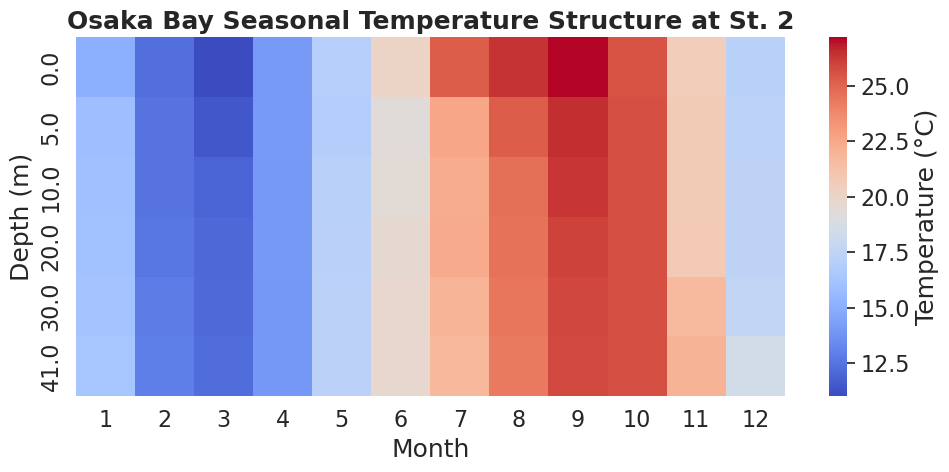

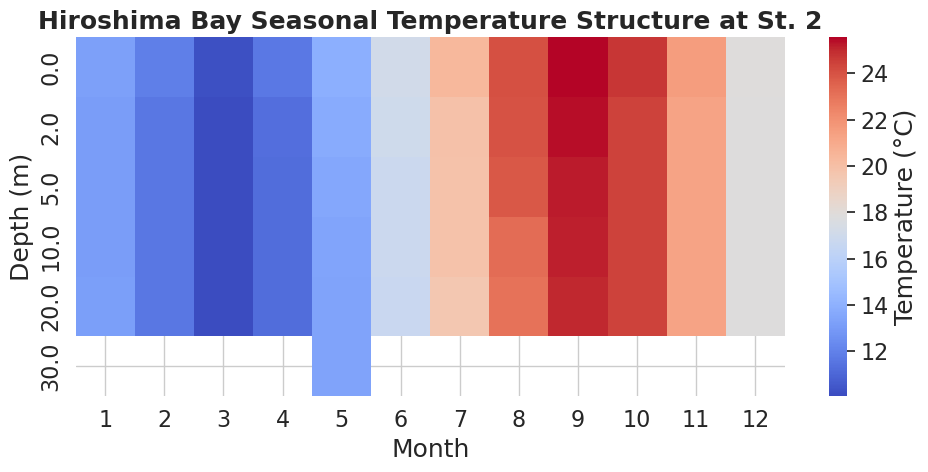

In [19]:
def plot_depth_time_heatmap(df, station_id, bay_name):
    # Filter data for the selected station
    st_data = df[df['Station'] == station_id].copy()
    st_data = st_data.dropna(subset=['Temperature', 'Numeric_Depth'])
    
    if st_data.empty:
        print(f"No data available for {bay_name} St. {station_id}.")
        return
        
    # Pivot to get Month vs Depth
    pivot_temp = st_data.pivot_table(index='Numeric_Depth', columns='Month', values='Temperature', aggfunc='mean')
    
    plt.figure(figsize=(10, 5))
    sns.heatmap(pivot_temp, cmap='coolwarm', cbar_kws={'label': 'Temperature (°C)'})
    plt.xlabel('Month')
    plt.ylabel('Depth (m)')
    plt.title(f'{bay_name} Seasonal Temperature Structure at St. {station_id}')
    plt.tight_layout()
    plt.show()

plot_depth_time_heatmap(df_osaka, station_id=2, bay_name='Osaka Bay')
plot_depth_time_heatmap(df_hiroshima, station_id=2, bay_name='Hiroshima Bay')

## 8. Figure 5: Temperature-Salinity (T-S) Diagrams

T-S diagrams allow us to visualize the density structure of the water column. We plot Temperature vs. Salinity and overlay constant density curves (isopycnals).

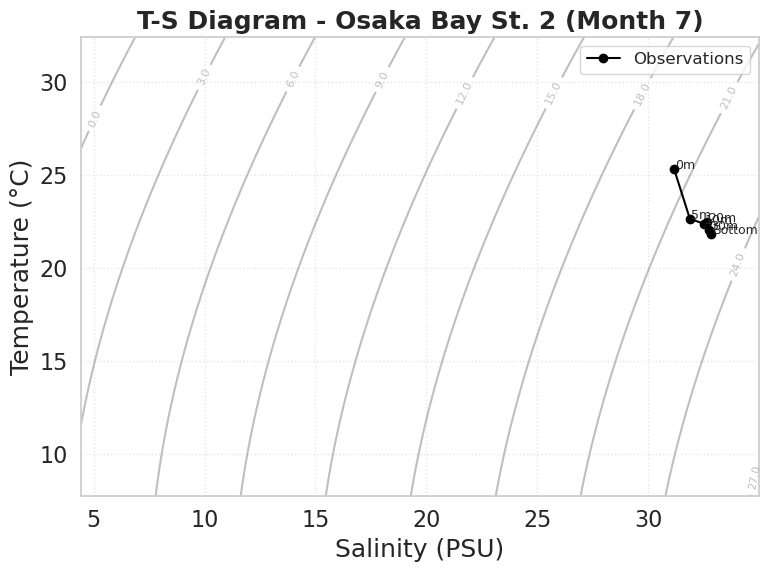

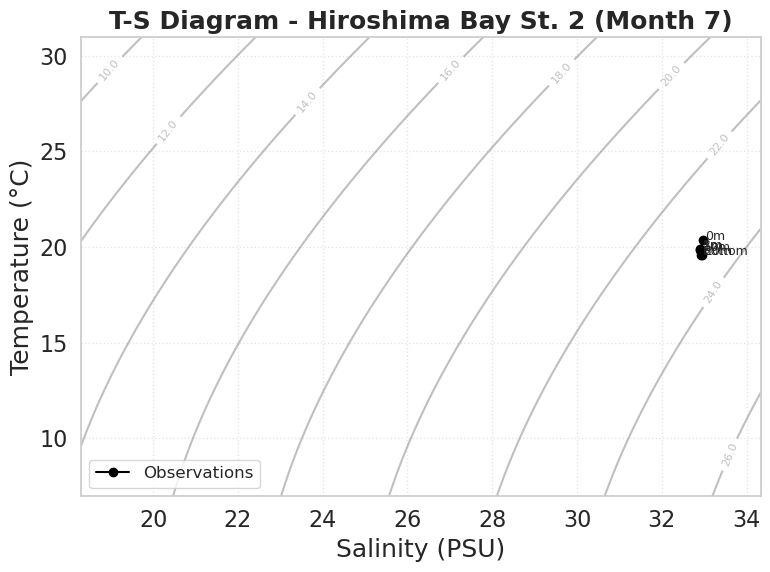

In [20]:
def plot_ts_diagram(df, station_id, month, bay_name):
    # Filter for specific station and month
    st_month_data = df[(df['Station'] == station_id) & (df['Month'] == month)].copy()
    st_month_data = st_month_data.dropna(subset=['Temperature', 'Salinity'])
    
    if st_month_data.empty:
        print(f"No TS data available for {bay_name} St. {station_id} in Month {month}.")
        return
        
    # Generate background density curves (isopycnals)
    s_min, s_max = df['Salinity'].min() - 1, df['Salinity'].max() + 1
    t_min, t_max = df['Temperature'].min() - 2, df['Temperature'].max() + 2
    
    s_grid, t_grid = np.mgrid[s_min:s_max:100j, t_min:t_max:100j]
    
    # Calculate density for the grid
    ref_lat = st_month_data['Latitude'].mean()
    ref_lon = st_month_data['Longitude'].mean()
    
    SA_grid = gsw.SA_from_SP(s_grid, 0, ref_lon, ref_lat)
    # Conservative Temperature
    CT_grid = gsw.CT_from_t(SA_grid, t_grid, 0)
    density_grid = gsw.sigma0(SA_grid, CT_grid)
    
    plt.figure(figsize=(8, 6))
    
    # Plot density contours in the background
    contours = plt.contour(s_grid, t_grid, density_grid, colors='gray', alpha=0.5, levels=10)
    plt.clabel(contours, inline=True, fontsize=8, fmt='%.1f')
    
    # Plot the TS points and line
    st_month_data = st_month_data.sort_values('Numeric_Depth')
    plt.plot(st_month_data['Salinity'], st_month_data['Temperature'], 'o-', color='black', label='Observations')
    
    # Annotate depths
    for _, row in st_month_data.iterrows():
        plt.text(row['Salinity'] + 0.05, row['Temperature'], f"{row['Depth']}", fontsize=9)
        
    plt.xlabel('Salinity (PSU)')
    plt.ylabel('Temperature (°C)')
    plt.title(f'T-S Diagram - {bay_name} St. {station_id} (Month {month})')
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.tight_layout()
    plt.show()

plot_ts_diagram(df_osaka, station_id=2, month=7, bay_name='Osaka Bay')
plot_ts_diagram(df_hiroshima, station_id=2, month=7, bay_name='Hiroshima Bay')